# PyTorch

## Задача
Используя PyTorch:

Создать и обучить регрессионную модель, которая аппроксимирует значение функции sin(x + 2*y)exp(-(2x + y)^2) на диапазоне значений [-10;10] по х и у.
В качестве обучающей выборки необходимо сгенерировать 20000 точек случайным образом.
Разделить получившийся датасет на train / test / val в отношениях 70% / 15% / 15%, соответственно.

Результаты:

a) Посчитать метрику Mean Square Error(MSE) на test.

b) Нарисовать график, в котором сравнивается истинная функция и ее аппроксимированный вариант (предсказываемый моделью).

In [1]:
import numpy as np
import copy, time
import torch
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn

In [2]:
torch.manual_seed(42)
np.random.seed(42)

## 2. Генерация данных

- target_fn(x, y) - функция, записанная PyTorch, которая считает значения сразу для всех точек.
- torch.empty(N, 2).uniform_(-10, 10) создаёт таблицу 20 000 * 2, заполненную равномерно распределёнными числами из [-10, 10]. Каждая строка является одной точкой (x, y).
- .unsqueeze(1) превращает вектор ответов формы (N,) в столбец (N, 1), чтобы форма совпадала с выходом модели.

In [3]:
def target_fn(x, y):
    return torch.sin(x + 2*y) * torch.exp(-(2*x + y)**2)

N = 20000

X = torch.empty(N, 2).uniform_(-10, 10)
Y = target_fn(X[:, 0], X[:, 1]).unsqueeze(1)

print("X:", X.shape, "Y:", Y.shape)
print("Y: min = %.4f, max = %.4f, mean = %.4f" % (Y.min(), Y.max(), Y.mean()))
print("Доля точек, где |Y| > 0.01:", (Y.abs() > 0.01).float().mean().item())

X: torch.Size([20000, 2]) Y: torch.Size([20000, 1])
Y: min = -0.9995, max = 0.9972, mean = -0.0009
Доля точек, где |Y| > 0.01: 0.09759999811649323


### Результат
- значения лежат в диапазоне [-1, 1], синус ограничен +- 1, экспонента не больше 1;
- среднее ~ 0;
- ~10% точек имеют |f| > 0.01. Функция отлична от нуля только в узкой полосе, почти везде равна нулю.

## 3. Визуализация функции и baseline

Строю функцию на регулярной сетке 400 * 400 (linspace + meshgrid) и рядом рисую сгенерированные точки, раскрашенные по значению функции. Палитра RdBu_r: синий - отрицательные значения, белый - ноль, красный - положительные.

Baseline - простейшая модель, которая всегда предсказывает 0. Её MSE равна mean(Y^2)

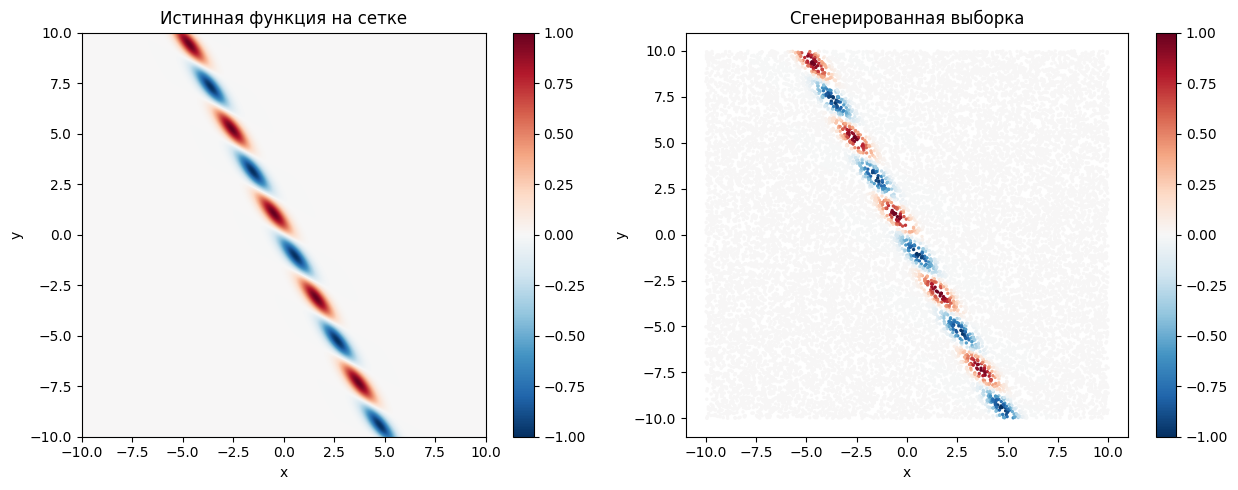

MSE константы 0: 0.01635


In [4]:
grid = torch.linspace(-10, 10, 400)
xx, yy = torch.meshgrid(grid, grid, indexing="xy")
zz = target_fn(xx, yy)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im = axes[0].imshow(zz, extent=[-10, 10, -10, 10], origin="lower",
                    cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_title("Истинная функция на сетке")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
fig.colorbar(im, ax=axes[0])

sc = axes[1].scatter(X[:, 0], X[:, 1], c=Y[:, 0], s=2,
                     cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_title("Сгенерированная выборка")
axes[1].set_xlabel("x"); axes[1].set_ylabel("y")
fig.colorbar(sc, ax=axes[1])

plt.tight_layout()
plt.show()

# Baseline
baseline_mse = (Y ** 2).mean().item()
print(f"MSE константы 0: {baseline_mse:.5f}")

### На графике:
- Функция сосредоточена в полосе шириной ~2 единицы вдоль прямой y = -2x.
- Внутри полосы чередуются красные и синие пятна. На отрезке x из [-5, 5] помещается ~10 пятен.
- Случайные точки покрывают квадрат равномерно, полоса в выборке хорошо различима.
- Baseline MSE ~ 0.016. Число маленькое, потому что функция почти везде равна нулю. Дальше сравниваю MSE моделей именно с этим значением.

## 4. Разбиение на train / val / test (70 / 15 / 15)

- train (14 000 точек) подбор весов для модели;
- val (3 000) по ним слежу за обучением и выбираю лучшую эпоху и лучшую модель;
- test (3 000) используется один раз в конце для честной оценки на данных, которые никак не влияли ни на веса, ни на решения.

torch.randperm(N) даёт случайную перестановку индексов, которую режу на три части. Test получает остаток, чтобы при округлении не потерять точки. Команды assert проверяют, что части не пересекаются.

In [5]:
perm = torch.randperm(N)

n_train = int(0.70 * N)
n_val   = int(0.15 * N)

idx_train = perm[:n_train]
idx_val   = perm[n_train:n_train + n_val]
idx_test  = perm[n_train + n_val:]

X_train, Y_train = X[idx_train], Y[idx_train]
X_val,   Y_val   = X[idx_val],   Y[idx_val]
X_test,  Y_test  = X[idx_test],  Y[idx_test]

for name, Yp in [("train", Y_train), ("val", Y_val), ("test", Y_test)]:
    print(f"{name:5s}: {len(Yp):5d} точек,"
          f"доля Y>0.01 = {(Yp.abs() > 0.01).float().mean():.3f},"
          f"baseline MSE = {(Yp**2).mean():.5f}")

assert len(set(idx_train.tolist()) & set(idx_test.tolist())) == 0
assert len(set(idx_train.tolist()) & set(idx_val.tolist())) == 0

train: 14000 точек,доля Y>0.01 = 0.097,baseline MSE = 0.01655
val  :  3000 точек,доля Y>0.01 = 0.097,baseline MSE = 0.01630
test :  3000 точек,доля Y>0.01 = 0.100,baseline MSE = 0.01548


Размеры 14 000 / 3 000 / 3 000. Доля полезных точек ~10% и baseline MSE во всех трёх частях примерно одинаковые; небольшие различия объясняются случайностью. Значит, разбиение не перекошено и выборки сопоставимы.

## 5. Нормализация входов и DataLoader

Нормализация: x' = (x - mean) / std. После неё каждый признак имеет среднее 0 и стандартное отклонение 1.

Среднее и std считаю только по train и затем применяю к val и test.

Целевую переменную Y не нормализую, она уже лежит в диапазоне [-1, 1], и MSE удобно считать в исходных единицах.

DataLoader нарезает данные на мини-батчи по 256 точек. Градиент считается по батчу. shuffle=True перемешивает train в каждой эпохе.

In [6]:
x_mean = X_train.mean(dim=0)
x_std  = X_train.std(dim=0)
print("mean:", x_mean, "\nstd:", x_std)

def normalize(X):
    return (X - x_mean) / x_std

X_train_n = normalize(X_train)
X_val_n   = normalize(X_val)
X_test_n  = normalize(X_test)

print("train после нормализации: mean =", X_train_n.mean(dim=0),
      "std =", X_train_n.std(dim=0))
print("диапазон:", X_train_n.min().item(), X_train_n.max().item())

batch_size = 256
train_loader = DataLoader(TensorDataset(X_train_n, Y_train),
                          batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_n, Y_val),
                          batch_size=1024, shuffle=False)

xb, yb = next(iter(train_loader))
print("один батч:", xb.shape, yb.shape, ",батчей в эпохе:", len(train_loader))

mean: tensor([ 0.0498, -0.0222]) 
std: tensor([5.7974, 5.7617])
train после нормализации: mean = tensor([ 6.9482e-09, -6.6757e-09]) std = tensor([1., 1.])
диапазон: -1.7334868907928467 1.7387290000915527
один батч: torch.Size([256, 2]) torch.Size([256, 1]) ,батчей в эпохе: 55


std ~ 5.77. После нормализации среднее равно 0, std равно 1, диапазон примерно +- 1.73. Батч имеет форму (256, 2) и (256, 1), в одной эпохе 55 батчей.

## 6. Модель 1: полносвязная сеть (MLP)

Сеть состоит из слоёв: 2 -> 128 -> 128 -> 128 -> 1.
на вход приходят 2 числа (x и y);
дальше три слоя по 128 нейронов. Каждый нейрон берёт числа из предыдущего слоя, умножает на свои веса, складывает и пропускает через функцию Tanh. Tanh нужна, чтобы сеть умела рисовать изогнутые поверхности; на выходе 1 число.

- nn.Linear(a, b) полносвязный слой, считает Wx + b.
- nn.Tanh() нелинейная функция активации между слоями.
- У выходного слоя активации нет.

Перед обучением проверяю форму выхода и MSE случайно инициализированной сети.

In [7]:
class MLP(nn.Module):
    def __init__(self, in_dim=2, hidden=128, n_layers=3, out_dim=1):
        super().__init__()
        layers = []
        dim = in_dim
        for _ in range(n_layers):
            layers += [nn.Linear(dim, hidden), nn.Tanh()]
            dim = hidden
        layers.append(nn.Linear(dim, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

n_params = sum(p.numel() for p in model.parameters())
print("Параметров:", n_params)

with torch.no_grad():
    out = model(xb)
    print("выход на батче:", out.shape)
    init_mse = ((model(X_val_n) - Y_val) ** 2).mean().item()
print(f"MSE необученной модели на val: {init_mse:.5f}")

MLP(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): Tanh()
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)
Параметров: 33537
выход на батче: torch.Size([256, 1])
MSE необученной модели на val: 0.01752


У сети 33 537 обучаемых параметров. Выход имеет форму (256, 1). MSE необученной сети порядка baseline, то есть данные и модель согласованы.

## 7. Обучение модели 1

Функция потерь MSELoss. Оптимизатор Adam (lr = 1e-3), он подстраивает шаг отдельно для каждого веса и устойчиво сходится. Scheduler ReduceLROnPlateau уменьшает learning rate вдвое, если val не улучшается 20 эпох.

Один шаг обучения:
1. optimizer.zero_grad() обнуляет старые градиенты;
2. model(xb) выполняет прямой проход и даёт предсказание;
3. criterion(pred, yb) считает ошибку;
4. loss.backward() вычисляет градиенты по всем весам;
5. optimizer.step() сдвигает веса в сторону уменьшения ошибки.

После каждой эпохи считаю MSE на val и запоминаю веса с наименьшей val-ошибкой.

In [8]:
torch.manual_seed(42)
model = MLP()

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=20)

def evaluate(model, loader):
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            total += criterion(model(xb), yb).item() * len(xb)
            n += len(xb)
    return total / n

n_epochs = 300
history = {"train": [], "val": []}
best_val, best_state, best_epoch = float("inf"), None, -1
t0 = time.time()

for epoch in range(1, n_epochs + 1):
    model.train()
    running, n = 0.0, 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(xb)
        n += len(xb)

    train_mse = running / n
    val_mse = evaluate(model, val_loader)
    scheduler.step(val_mse)
    history["train"].append(train_mse)
    history["val"].append(val_mse)

    if val_mse < best_val:
        best_val, best_epoch = val_mse, epoch
        best_state = copy.deepcopy(model.state_dict())

    if epoch % 25 == 0 or epoch == 1:
        lr = optimizer.param_groups[0]["lr"]
        print(f"epoch {epoch:3d}, train {train_mse:.6f}, val {val_mse:.6f}, lr {lr:.1e}")

epoch   1, train 0.018267, val 0.016422, lr 1.0e-03
epoch  25, train 0.016475, val 0.016235, lr 1.0e-03
epoch  50, train 0.016295, val 0.016120, lr 1.0e-03
epoch  75, train 0.016041, val 0.016228, lr 1.0e-03
epoch 100, train 0.015842, val 0.015382, lr 1.0e-03
epoch 125, train 0.015704, val 0.015505, lr 1.0e-03
epoch 150, train 0.015575, val 0.015203, lr 5.0e-04
epoch 175, train 0.015425, val 0.015366, lr 5.0e-04
epoch 200, train 0.015380, val 0.015172, lr 2.5e-04
epoch 225, train 0.015308, val 0.015165, lr 1.3e-04
epoch 250, train 0.015246, val 0.015063, lr 6.3e-05
epoch 275, train 0.015208, val 0.015034, lr 3.1e-05
epoch 300, train 0.015198, val 0.015013, lr 1.6e-05


In [9]:
print(f"Время: {time.time() - t0:.0f}сек, лучший val = {best_val:.6f} на эпохе {best_epoch}")

Время: 98сек, лучший val = 0.014951 на эпохе 203


### Кривые обучения модели 1

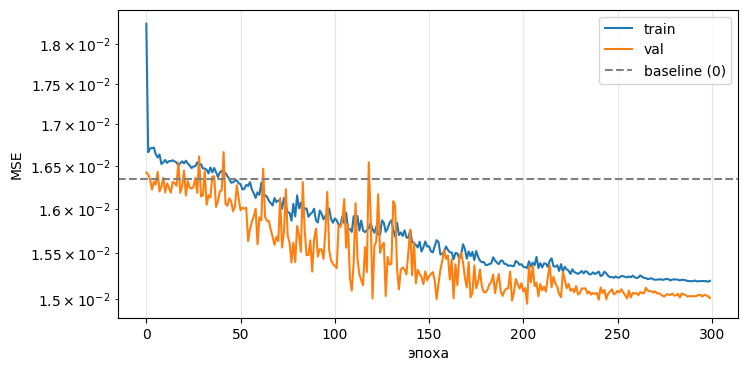

In [10]:
model.load_state_dict(best_state)

plt.figure(figsize=(8, 4))
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="val")
plt.axhline(baseline_mse, color="gray", ls="--", label="baseline (0)")
plt.yscale("log"); plt.xlabel("эпоха"); plt.ylabel("MSE")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Результат
Кривые train и val почти не опускаются ниже пунктирной линии baseline. За 300 эпох MSE снизилась лишь примерно на 8% относительно предсказания "всегда 0". Кривые train и val идут рядом - значит, переобучения нет. Это недообучение: модель не способна выучить функцию.

## 8. Что выучила модель 1

Чтобы понять, где модель ошибается, строю три карты: истинная функция, предсказание и ошибка (pred - true). Точки сетки перед подачей в модель нормализуются тем же преобразованием, что и train.

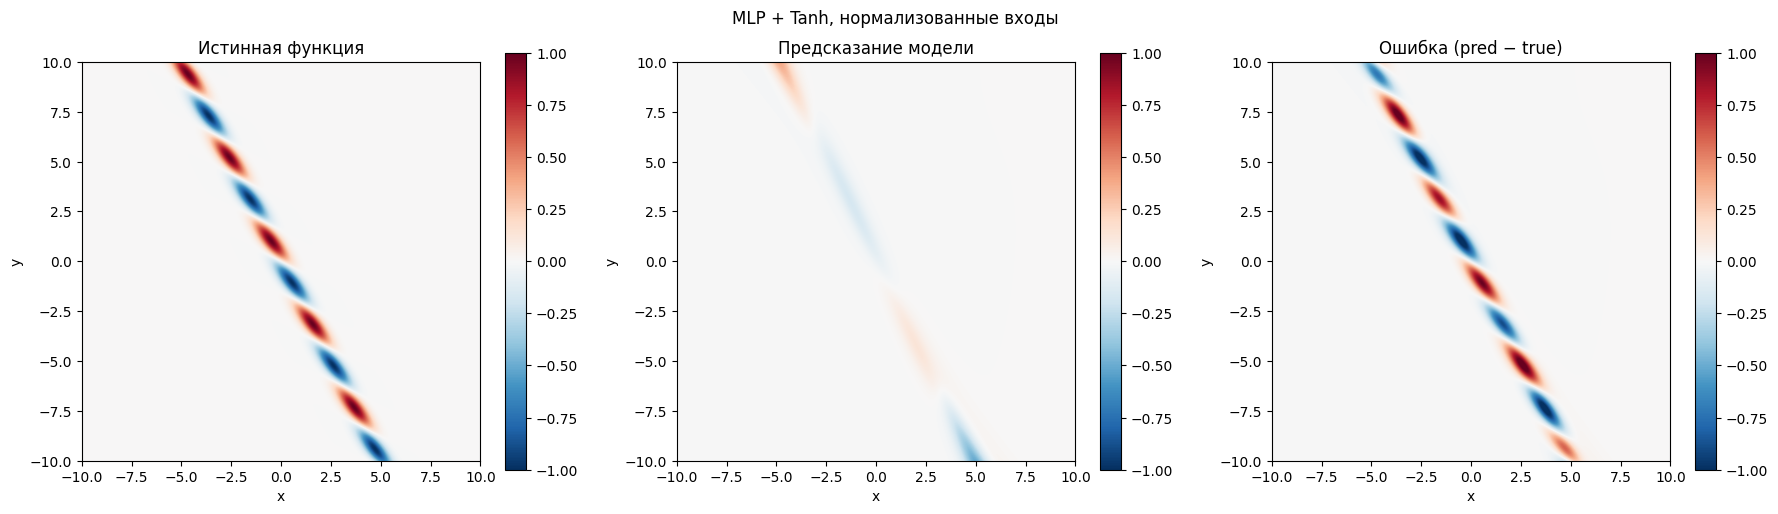

Диапазон предсказаний: [-0.509, 0.386]


In [11]:
def plot_comparison(model, normalize_fn, title=""):
    grid = torch.linspace(-10, 10, 400)
    xx, yy = torch.meshgrid(grid, grid, indexing="xy")
    pts = torch.stack([xx.flatten(), yy.flatten()], dim=1)

    model.eval()
    with torch.no_grad():
        zz_pred = model(normalize_fn(pts)).reshape(400, 400)
    zz_true = target_fn(xx, yy)
    err = zz_pred - zz_true

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    panels = [(zz_true, "Истинная функция"),
              (zz_pred, "Предсказание модели"),
              (err,     "Ошибка (pred − true)")]
    for ax, (z, name) in zip(axes, panels):
        im = ax.imshow(z, extent=[-10, 10, -10, 10], origin="lower",
                       cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_title(name); ax.set_xlabel("x"); ax.set_ylabel("y")
        fig.colorbar(im, ax=ax)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

    print("Диапазон предсказаний: [%.3f, %.3f]" % (zz_pred.min(), zz_pred.max()))

plot_comparison(model, normalize, "MLP + Tanh, нормализованные входы")

### Модель 1 не справилась

На средней карте видны только бледные пятна, предсказания не выходят за +- 0.5 при истинных +- 1. Карта ошибки повторяет истинную функцию, модель в основном предсказывает ноль.

Причины:
1. Нормализация сжала детали. Чтобы нарисовать мелкие детали, сети пришлось бы сильно увеличить веса, а градиентный спуск делает это медленно.
3. 90% точек имеют Y ~ 0 и их градиенты тянут модель к предсказанию нуля.
4. Scheduler снижал learning rate.

## 9. Модель 2: MLP с Fourier features

Вместо координат v = (x, y) подаю сети набор синусоид разных частот и направлений:

gamma(v) = [sin(2pi B v), cos(2pi B v)],

где B - это случайная матрица 2 * 128 с элементами из N(0, сигма^2).

- сигма = 1 задаёт типичную частоту волн.
- register_buffer сохраняет матрицу B вместе с моделью, но не обучает её.
- После признаков идёт та же MLP, что и в модели 1.

Также заменён scheduler на CosineAnnealingLR - learning rate уменьшается по косинусу от 1e-3 до 0 за 300 эпох и не падает преждевременно из-за шума val. Цикл обучения вынесен в функцию train_model.

Параметров: 66049
epoch   1, train 0.011009, val 0.009320 lr 1.0e-03
epoch  25, train 0.000067, val 0.000085 lr 9.8e-04
epoch  50, train 0.000035, val 0.000036 lr 9.3e-04
epoch  75, train 0.000038, val 0.000033 lr 8.5e-04
epoch 100, train 0.000027, val 0.000028 lr 7.5e-04
epoch 125, train 0.000019, val 0.000018 lr 6.3e-04
epoch 150, train 0.000019, val 0.000017 lr 5.0e-04
epoch 175, train 0.000006, val 0.000011 lr 3.7e-04
epoch 200, train 0.000005, val 0.000004 lr 2.5e-04
epoch 225, train 0.000001, val 0.000001 lr 1.5e-04
epoch 250, train 0.000001, val 0.000001 lr 6.7e-05
epoch 275, train 0.000000, val 0.000001 lr 1.7e-05
epoch 300, train 0.000000, val 0.000001 lr 0.0e+00

Время: 116 cек, лучший val = 0.000001 на эпохе 290


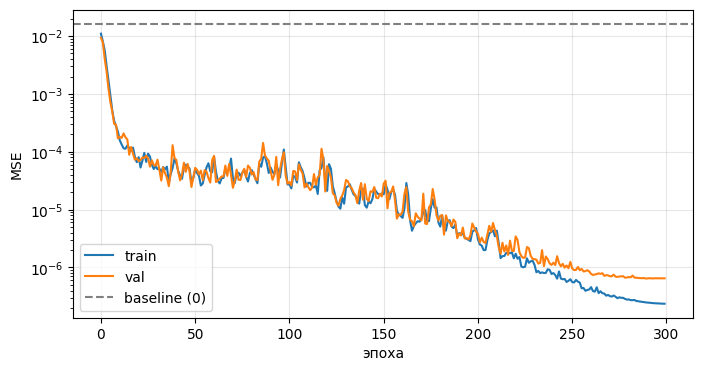

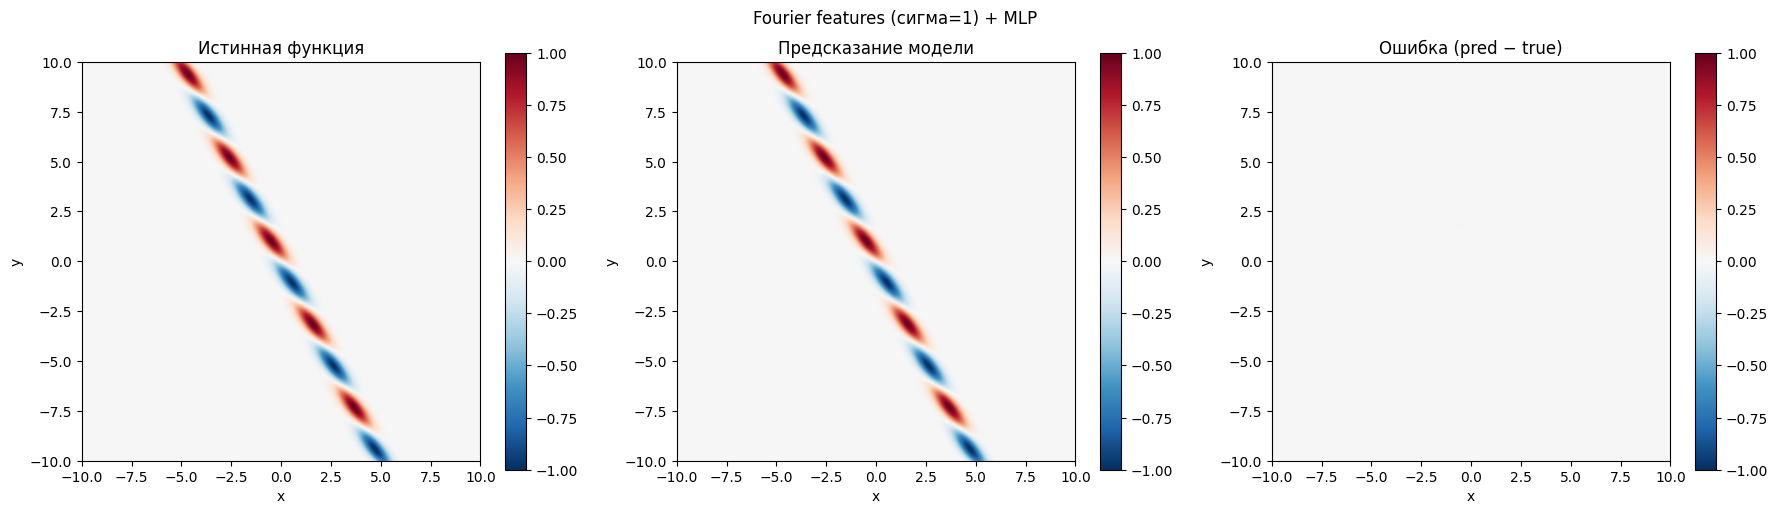

Диапазон предсказаний: [-0.999, 0.999]


In [12]:
class FourierMLP(nn.Module):
    def __init__(self, in_dim=2, n_freq=128, sigma=1.0, hidden=128, n_layers=3):
        super().__init__()
        self.register_buffer("B", torch.randn(in_dim, n_freq) * sigma)
        self.mlp = MLP(in_dim=2 * n_freq, hidden=hidden, n_layers=n_layers)

    def forward(self, x):
        proj = 2 * torch.pi * x @ self.B
        feats = torch.cat([torch.sin(proj), torch.cos(proj)], dim=1)
        return self.mlp(feats)


def train_model(model, n_epochs=300, lr=1e-3, log_every=25):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
    history = {"train": [], "val": []}
    best_val, best_state, best_epoch = float("inf"), None, -1
    t0 = time.time()

    for epoch in range(1, n_epochs + 1):
        model.train()
        running, n = 0.0, 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb); n += len(xb)
        scheduler.step()

        train_mse, val_mse = running / n, evaluate(model, val_loader)
        history["train"].append(train_mse); history["val"].append(val_mse)
        if val_mse < best_val:
            best_val, best_epoch = val_mse, epoch
            best_state = copy.deepcopy(model.state_dict())
        if epoch % log_every == 0 or epoch == 1:
            print(f"epoch {epoch:3d}, train {train_mse:.6f}, val {val_mse:.6f} "
                  f"lr {optimizer.param_groups[0]['lr']:.1e}")

    model.load_state_dict(best_state)
    print(f"\nВремя: {time.time()-t0:.0f} cек, лучший val = {best_val:.6f} на эпохе {best_epoch}")
    return history


torch.manual_seed(42)
model_ff = FourierMLP(sigma=1.0)
print("Параметров:", sum(p.numel() for p in model_ff.parameters()))
hist_ff = train_model(model_ff, n_epochs=300)

plt.figure(figsize=(8, 4))
plt.plot(hist_ff["train"], label="train"); plt.plot(hist_ff["val"], label="val")
plt.axhline(baseline_mse, color="gray", ls="--", label="baseline (0)")
plt.yscale("log"); plt.xlabel("эпоха"); plt.ylabel("MSE")
plt.legend(); plt.grid(alpha=0.3); plt.show()

plot_comparison(model_ff, normalize, "Fourier features (сигма=1) + MLP")

### Анализ обучения модели 2

**Кривая обучения:**
- в первые ~20 эпох MSE резко падает с 1e-2 до 1e-4;
- примерно до 150-й эпохи MSE колеблется около 1e-5 - 1e-4;
- когда косинусный scheduler уменьшает шаг, модель уточняет детали, и val MSE опускается до ~1e-6.

## 10. Результат 1: MSE на test

Test используется впервые. Все решения (архитектура, сигма, scheduler, выбор эпохи) принимаются по val.

RMSE = sqrt(MSE) показывает ошибку в исходных единицах функции.

In [13]:
# MSE на test
test_loader = DataLoader(TensorDataset(X_test_n, Y_test), batch_size=1024, shuffle=False)

test_mse = evaluate(model_ff, test_loader)
baseline_test = (Y_test ** 2).mean().item()

print(f"MSE на test: {test_mse:.3e}")
print(f"RMSE на test: {test_mse ** 0.5:.3e}")
print(f"Baseline (0) на test: {baseline_test:.3e}")
print(f"Модель лучше baseline в {baseline_test / test_mse:.0f} раз")
print(f"Первая модель (MLP + Tanh) на test: {evaluate(model, test_loader):.3e}")

MSE на test: 8.659e-07
RMSE на test: 9.306e-04
Baseline (0) на test: 1.548e-02
Модель лучше baseline в 17881 раз
Первая модель (MLP + Tanh) на test: 1.417e-02


### Результаты на test

- В среднем модель ошибается примерно на 0.1% от амплитуды функции (амплитуда равна 1).
- Модель 2 лучше baseline примерно в 18 000 раз.
- MSE на test того же порядка, что на val, модель хорошо обобщает на новые данные.
- R^2 = 1 - MSE/Var(Y) ~ 0.9999. Модель объясняет 99.99% разброса значений функции.

## 11. Результат 2: сравнение истинной функции и аппроксимации

Три графика:
1. Истинная функция, предсказание и ошибка в общей шкале [-1, 1].
2. Ошибка в собственной шкале, чтобы было видно, где модель ошибается.
3. Срез вдоль центральной прямой полосы y = -2x: истинная кривая (толстая линия) и предсказание (пунктир).

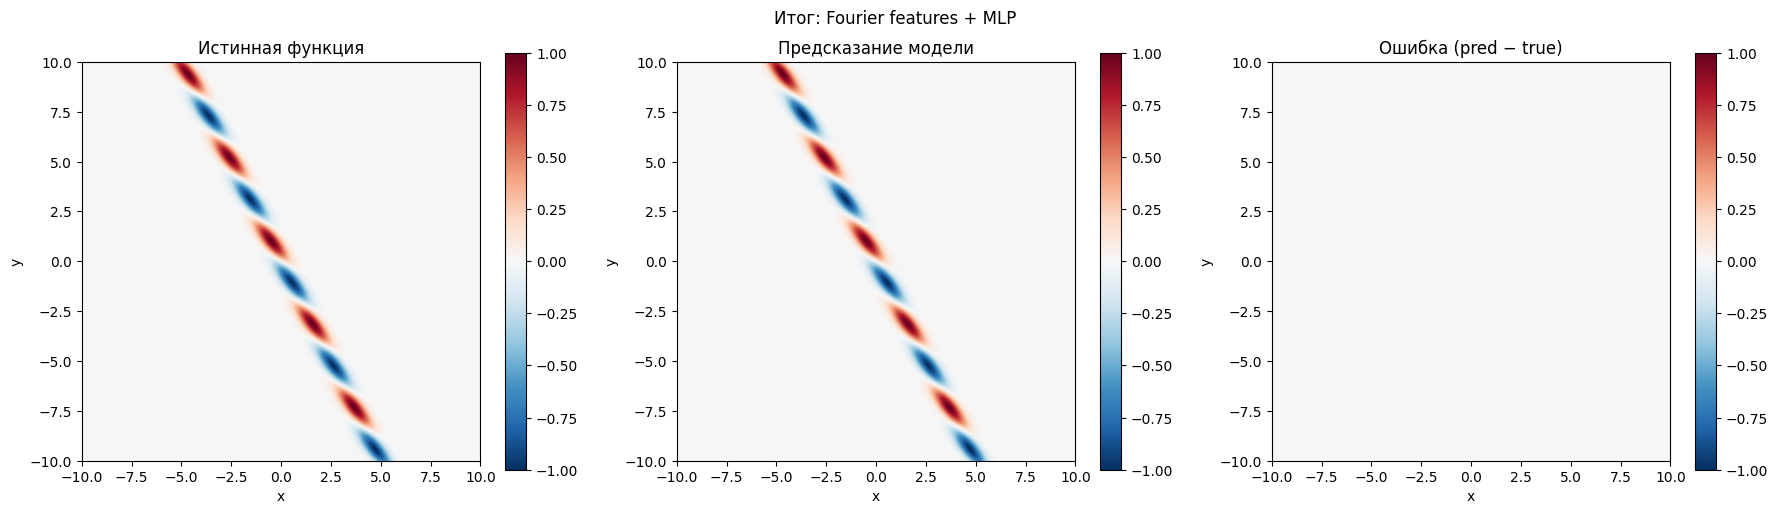

Диапазон предсказаний: [-0.999, 0.999]


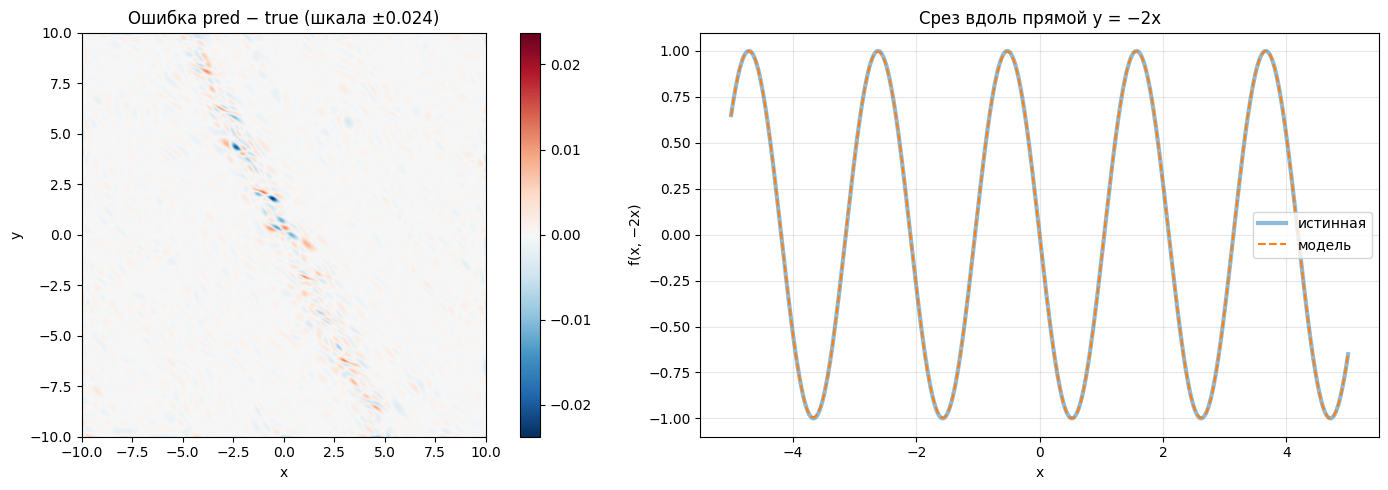

In [14]:
# График сравнения
plot_comparison(model_ff, normalize, "Итог: Fourier features + MLP")

grid = torch.linspace(-10, 10, 400)
xx, yy = torch.meshgrid(grid, grid, indexing="xy")
pts = torch.stack([xx.flatten(), yy.flatten()], dim=1)
model_ff.eval()
with torch.no_grad():
    zz_pred = model_ff(normalize(pts)).reshape(400, 400)
err = zz_pred - target_fn(xx, yy)
lim = err.abs().max().item()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
im = axes[0].imshow(err, extent=[-10, 10, -10, 10], origin="lower",
                    cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[0].set_title(f"Ошибка pred − true (шкала ±{lim:.3f})")
axes[0].set_xlabel("x"); axes[0].set_ylabel("y")
fig.colorbar(im, ax=axes[0])

# Срез вдоль центральной прямой y = -2x
t = torch.linspace(-5, 5, 500)
line = torch.stack([t, -2 * t], dim=1)
with torch.no_grad():
    pred_line = model_ff(normalize(line)).squeeze()
true_line = target_fn(line[:, 0], line[:, 1])

axes[1].plot(t, true_line, lw=3, alpha=0.5, label="истинная")
axes[1].plot(t, pred_line, "--", lw=1.5, label="модель")
axes[1].set_title("Срез вдоль прямой y = −2x")
axes[1].set_xlabel("x"); axes[1].set_ylabel("f(x, −2x)")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Результат
- Предсказание модели визуально неотличимо от истинной функции.
- В собственной шкале видно, что ошибка сосредоточена внутри полосы, где функция меняется быстрее всего.

## Выводы

1. Особенность функции. f(x, y) заметно отлична от нуля только в узкой полосе вокруг прямой y = -2x (~10% площади).

2. Модель 1 (MLP 3*128, Tanh, Adam, ReduceLROnPlateau) достигла MSE на test ~ 1.4e-2, что почти не отличается от baseline. Модель недообучилась, обычный MLP плохо выучивает высокочастотные детали (spectral bias), а 90% нулевых точек тянут предсказание к нулю.

3. Модель 2 (Fourier features, 128 частот, сигма = 1, + тот же MLP, Adam, CosineAnnealingLR) достигла MSE на test = 8.66e-7 (RMSE ~ 9.3e-4, R^2 ~ 0.9999). Это ~ в 18 000 раз лучше baseline, предсказание визуально совпадает с истинной функцией.

4. Лучшие веса выбирались по val, test использовался только для итоговой оценки.

5. MLP не помогло ни увеличение числа эпох, ни подбор learning rate, а Fourier features решило задачу.